# UNSUPERVISED DEEP LEARNING (AIMLZG533)
# Assignment 2 - Image Generation using (β-)VAE, VQ-VAE and WGAN

**PRICILLA W           -  2025AE05321**

**GUNA ANBAN G         -  2025AE05318**

**PUNEET SINGHAL       - 2025AE05340**

**CHOKKARAP PRAVEEN    - 2025AF05151**

**YUVRAJ KISHAN SHARMA - 2025AG05143**


## Part A: (β-)VAE & VQ-VAE Framework Analysis

### Experimental Overview & Metrics
* **Reconstruction vs. Regularization (β-VAE):** Evaluate reconstruction quality (PSNR) and distribution alignment (FID) across $\beta \in \{1, 2, 4, 10\}$ to observe the trade-off between latent regularization and image detail.
* **Discrete Latent Sampling (VQ-VAE):** Train VQ-VAE models using codebook sizes $K \in \{512, 256, 128\}$. Report codebook perplexity and active code utilization.
* **Autoregressive Prior:** Train a PixelCNN prior over discrete latent maps extracted from the training set, followed by latent decoding for unconditional generation.
* **Evaluation Protocol:** FID scores are calculated using the 10,000-image evaluation setup against the CIFAR-10 test split.

In [2]:
!pip install "torchmetrics[image]" torch-fidelity
from pathlib import Path
import sys
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Image

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "assignment2_solution.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Place this notebook and assignment2_solution.py in the same folder.")
sys.path.insert(0, str(ROOT))
from assignment2_solution import run_part_a

if not torch.cuda.is_available():
    raise RuntimeError("Use the BITS-provisioned CUDA GPU runtime for this assignment.")
print("GPU:", torch.cuda.get_device_name(0))
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "outputs"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 55.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [torch-fidelity]m [torch-fidelity]
GPU: NVIDIA RTX A6000


### Execution & Training Configuration
Default training uses 100 epochs per VAE/VQ-VAE and 50 epochs per PixelCNN. FID calculations rely on the Inception feature extractor supplied by TorchMetrics/torch-fidelity; note that the first execution may take a moment to fetch the pretrained weights.

In [4]:
from assignment2_solution import run_part_a
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "outputs"
results_a = run_part_a(
    data_dir=DATA_DIR,
    output_dir=OUTPUT_DIR,
    vae_epochs=100,
    vqvae_epochs=100,
    pixelcnn_epochs=50,
)
display(list(results_a.values()))


vae_beta_1 | epoch 001/100 | loss=115.177 | test PSNR=17.35 dB
vae_beta_1 | epoch 002/100 | loss=85.804 | test PSNR=17.83 dB
vae_beta_1 | epoch 003/100 | loss=81.442 | test PSNR=17.99 dB
vae_beta_1 | epoch 004/100 | loss=79.890 | test PSNR=18.12 dB
vae_beta_1 | epoch 005/100 | loss=78.985 | test PSNR=18.20 dB
vae_beta_1 | epoch 006/100 | loss=78.326 | test PSNR=18.31 dB
vae_beta_1 | epoch 007/100 | loss=77.839 | test PSNR=18.40 dB
vae_beta_1 | epoch 008/100 | loss=77.436 | test PSNR=18.36 dB
vae_beta_1 | epoch 009/100 | loss=77.147 | test PSNR=18.37 dB
vae_beta_1 | epoch 010/100 | loss=76.854 | test PSNR=18.42 dB
vae_beta_1 | epoch 011/100 | loss=76.746 | test PSNR=18.45 dB
vae_beta_1 | epoch 012/100 | loss=76.463 | test PSNR=18.42 dB
vae_beta_1 | epoch 013/100 | loss=76.393 | test PSNR=18.38 dB
vae_beta_1 | epoch 014/100 | loss=76.253 | test PSNR=18.43 dB
vae_beta_1 | epoch 015/100 | loss=76.184 | test PSNR=18.43 dB
vae_beta_1 | epoch 016/100 | loss=75.957 | test PSNR=18.42 dB
vae_bet

[{'model_id': 'vae_beta_1',
  'family': 'VAE',
  'beta': 1,
  'epochs': 100,
  'test_psnr_db': 18.683084490728245,
  'fid': 188.03611755371094,
  'training_seconds': 397.2064442001865,
  'seconds_per_epoch': 3.9720644420018654,
  'fid_images': 10000,
  'checkpoint': 'C:\\Users\\laptop\\Desktop\\Assignment2_Solution\\New folder\\outputs\\checkpoints\\vae_beta_1.pt'},
 {'model_id': 'vae_beta_2',
  'family': 'VAE',
  'beta': 2,
  'epochs': 100,
  'test_psnr_db': 17.569480508204826,
  'fid': 245.39349365234375,
  'training_seconds': 349.7896886995877,
  'seconds_per_epoch': 3.497896886995877,
  'fid_images': 10000,
  'checkpoint': 'C:\\Users\\laptop\\Desktop\\Assignment2_Solution\\New folder\\outputs\\checkpoints\\vae_beta_2.pt'},
 {'model_id': 'vae_beta_4',
  'family': 'VAE',
  'beta': 4,
  'epochs': 100,
  'test_psnr_db': 16.468630423759592,
  'fid': 300.0365295410156,
  'training_seconds': 341.20709640008863,
  'seconds_per_epoch': 3.412070964000886,
  'fid_images': 10000,
  'checkpoint

## PSNR curves and generated examples

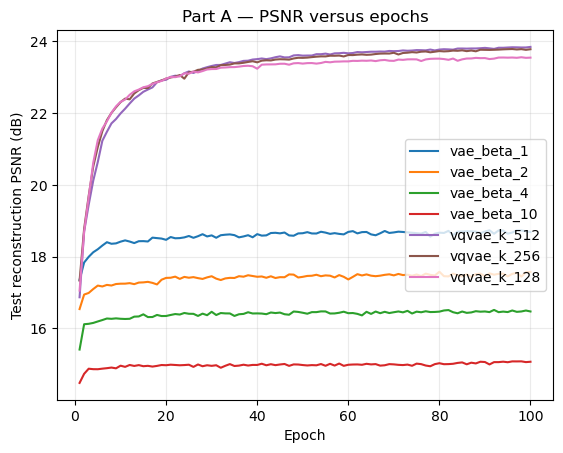

vae_beta_1 — 100 samples


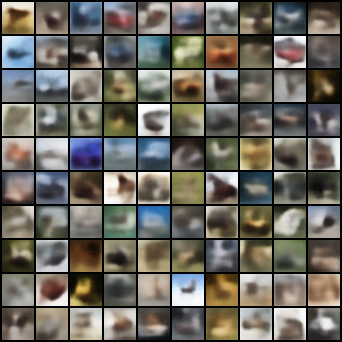

vqvae_k_512 — 100 samples


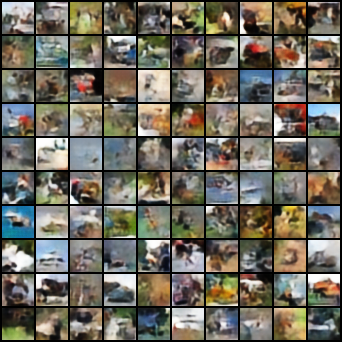

vqvae_k_256 — 100 samples


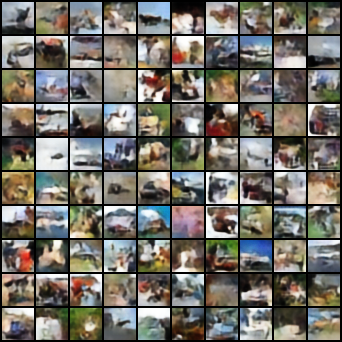

vqvae_k_128 — 100 samples


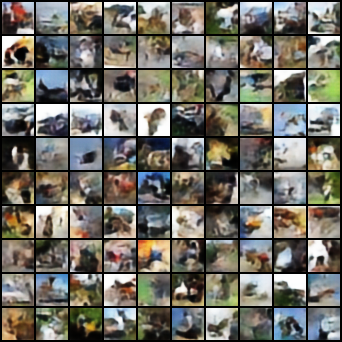

In [5]:
import json

for name in (
    "vae_beta_1", "vae_beta_2", "vae_beta_4", "vae_beta_10",
    "vqvae_k_512", "vqvae_k_256", "vqvae_k_128",
):
    with (OUTPUT_DIR / "curves" / f"{name}.json").open() as f:
        curve = json.load(f)
    plt.plot(curve["epoch"], curve["psnr"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Test reconstruction PSNR (dB)")
plt.title("Part A — PSNR versus epochs")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

for name in ("vae_beta_1", "vqvae_k_512", "vqvae_k_256", "vqvae_k_128"):
    print(name, "— 100 samples")
    display(Image(filename=str(OUTPUT_DIR / "samples" / f"{name}_100.png")))
